Define repositório

In [1]:
import json
import csv

class File:

  def __init__(self, path):
    self.path = path

  def read(self):
    with open(self.path, "r") as file:
      if self.path.endswith(".json"):
        return json.load(file)
      elif self.path.endswith(".csv"):
        result = []
        reader = csv.DictReader(file)
        for row in reader:
          result.append(row)
        return result
        
    return None

  def write(self, data):
    with open(self.path, "w") as file:
      if self.path.endswith(".json"):
        json.dump(data, file, indent = 2, sort_keys=True)
        print(f"> write {self.path}")

import os

class Folder:

  def __init__(self, base):
    self.base = base

  def all_files(self):
    result = []
    self.__all_files_recursive(result, self.base)
    return result

  def __all_files_recursive(self, result, folder):
    for file in os.listdir(folder):
      if os.path.isdir(f"{folder}/{file}"):
        self.__all_files_recursive(result, f"{folder}/{file}")
      else: 
        filepath = os.path.join(folder, file)
        result.append(filepath)
        

  def all_files_by_ext(self, ext=".json"):
    result = []
    for file in self.all_files():
      if file.endswith(ext):
        result.append(file)
    return result

  def all_files_with_pattern(self, pattern):
    result = []
    for file in self.all_files():
      if pattern in file:
        result.append(file)
    return result
  
  def file(self, path):
    return File(path)

  def create(self):
    if not os.path.exists(self.base):
      os.makedirs(self.base)

  

In [2]:
base = "drive/My Drive/Colab Notebooks"
repository = "gson"

inicio = 1
fim = 1400

Leitura do arquivo de commits

In [3]:
commits_file = File(f"{base}/metadata/{repository}/commits.json").read()
#commits_file[:5]

In [ ]:
#ler arquivo zip
import zipfile
import json

#multipattern_zip = zipfile.ZipFile(f"{base}/metadata/{repository}/multipattern.zip", "r")
def read_file_from_zip(zipfile, file):
  data = zipfile.read(file)
  return json.loads(data.decode("utf-8"))

Define função de leitura de ZIP

Contagem dos tipos de mapeamentos por commit

In [ ]:
mapeamentos_zip = zipfile.ZipFile(f"{base}/metadata/{repository}/mappings.zip")
result = mapeamentos_zip.namelist()[:10]
#print(result)

resultado = []
for commit in commits_file[inicio:fim]:
  tipos = {
      "insert": 0,
      "delete": 0,
      "update": 0,
      "move": 0
  }
  file = read_file_from_zip(mapeamentos_zip, f"{commit}.json")
  for mapping in file["mappings"]:
    type = mapping["type"]
    tipos[type] = tipos[type] + 1
  resultado.append(tipos)

mapeamentos_zip.close()


In [ ]:
resultado[:5]

[{'delete': 0, 'insert': 0, 'move': 0, 'update': 0},
 {'delete': 0, 'insert': 0, 'move': 0, 'update': 0},
 {'delete': 0, 'insert': 36, 'move': 0, 'update': 0},
 {'delete': 0, 'insert': 0, 'move': 0, 'update': 0},
 {'delete': 0, 'insert': 0, 'move': 0, 'update': 0}]

Gráfico de Contagem de Tipos de Mapemantos por Commit

In [ ]:
insert = []
delete = []
update = []
move = []

for item in resultado:
  insert.append(item["insert"])
  delete.append(item["delete"])
  update.append(item["update"])
  move.append(item["move"])

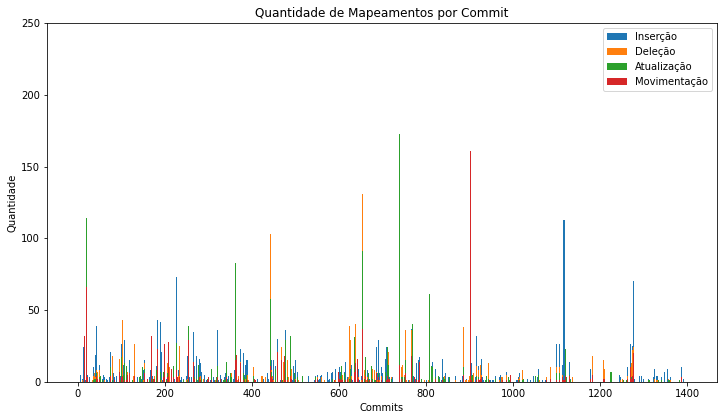

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fig = plt.gcf()
fig.set_size_inches(12, 6.6)

tamanho = fim - inicio
indices = np.arange(tamanho)

pInsert = plt.bar(indices, insert)
pDelete = plt.bar(indices, delete)
pUpdate = plt.bar(indices, update)
pMove = plt.bar(indices, move)

plt.title("Quantidade de Mapeamentos por Commit")
plt.ylabel("Quantidade")
plt.xlabel("Commits")
plt.ylim(top=250)

plt.legend((pInsert[0],pDelete[0], pUpdate[0], pMove[0]), ('Inserção','Deleção', 'Atualização', 'Movimentação'))

plt.show()

Define gráfico Multipattern

In [ ]:
from google.colab import files

def plot(x, data1, data2):
  fig, ax1 = plt.subplots()
  ax1.set_xlabel('Commit')
  
  color = 'tab:red'
  ax1.set_ylabel('Quantidade', color=color)
  ax1.plot(x, data1, color=color)
  ax1.tick_params(axis='y', labelcolor=color)

  color = 'tab:blue'
  ax2 = ax1.twinx()
  ax2.set_ylabel('Média da variação da manut.\n por commit', color=color)  # we already handled the x-label with ax1
  ax2.plot(x, data2, color=color)
  ax2.tick_params(axis='y', labelcolor=color)

  #plt.title("Quantidade de Modificações e Variação da\n Manutenabilidade por commit")
  fig.set_size_inches(12, 6.6)
  #plt.show()
  plt.savefig("multipattern.pdf",  bbox_inches='tight')
  files.download("multipattern.pdf")

Gerar gráfico

In [ ]:
data_file = File(f"{base}/metadata/{repository}/analise-multipattern.json").read()
posicoes = np.arange(start=inicio, stop=fim, step=1)
quantidades = []
medias = []

for commit in commits_file[inicio:fim]:
  if commit in data_file:
    values = data_file[commit].values()
    quantidade = len(values)
    media = 0
    for value in values:
      media = media + value
    media = media/quantidade
  else:
    media = 0
    quantidade = 0
  quantidades.append(quantidade)
  medias.append(media)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

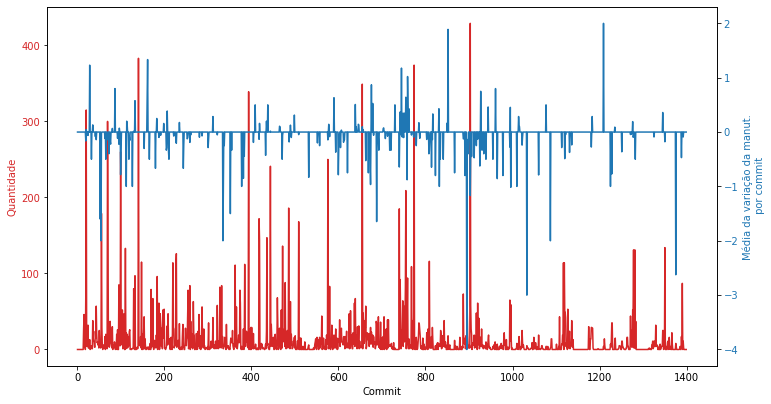

In [ ]:
plot(posicoes, quantidades, medias)

Define função do gráfico de Distribuição de Manutenabilidade por Padrão de Modificação

In [ ]:
def plot_box(keys, values):
    fig, ax = plt.subplots()
    bp = ax.boxplot(
        values, 
        sym='k+'
    )

    ax.set_xlabel('Padrões de Modificação')
    ax.set_ylabel('Dist. do Índice de Manutenabilidade')
    plt.setp(bp['whiskers'], color='k', linestyle='-')
    plt.setp(bp['fliers'], markersize=3.0)
    plt.title("Distribuição de Manutenabilidade por Padrão de Modificação")

    plt.xticks(np.arange(len(keys))+1, keys, rotation=55)
    fig.set_size_inches(15, 8)
    #plt.show()
    plt.savefig("boxplot-arquivos.pdf",  bbox_inches='tight')
    files.download("boxplot-arquivos.pdf")

Processamento da Distribuição de Manutenabilidade

In [ ]:
file = File(f"{base}/metadata/{repository}/clusters-manutenabilidade.json")
clusters = file.read()


# Lista dos maiores agrupamentos de cada repositorio

# In[19]:


arquivo = File(f"{base}/metadata/{repository}/distribuicao-tamanhos-clusters.json").read()
conjunto = []
sizes = []
for tamanho, data in arquivo.items():
    tamanho = int(tamanho)
    sizes.insert(0, tamanho)
    if tamanho > 1:
        for item in data["items"]:
            conjunto.insert(0, item)

Box plot das 50 modificações com maior ocorrência

In [ ]:
#seleciona os 50 maiores agrupamentos (somente move e updates)
import statistics

clusters_zip = zipfile.ZipFile(f"{base}/metadata/{repository}/clusters.zip")

result = {}
for index in conjunto[:50]:
  cluster = read_file_from_zip(clusters_zip, f"clusters/{index}.json")
  adicionar = False
  for item in cluster["base"]["items"]:
    if item["type"] == "move" or item["type"] == "update":
      adicionar = True
  
  if adicionar:
    result[index] = clusters[index]["indexes"]

elementos = {k: v for k, v in sorted(result.items(), key=lambda item: statistics.mean(item[1]))}

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

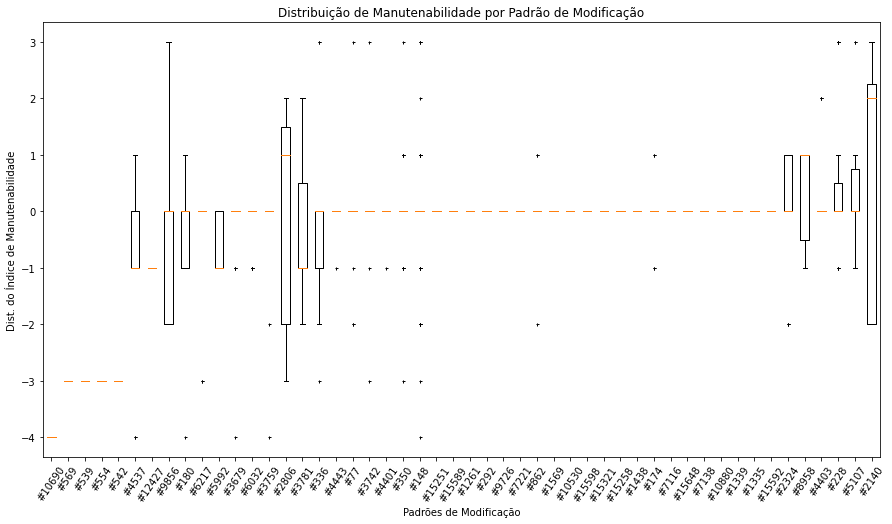

In [ ]:
all_keys = list(elementos.keys())
all_values = list(elementos.values())
plot_box(all_keys, all_values)

Lista de padrões de modificações com número de ocorrências >= 2

In [ ]:
result = {}
for index in conjunto:
  cluster = read_file_from_zip(clusters_zip, f"clusters/{index}.json")
  adicionar = False
  for item in cluster["base"]["items"]:
    if item["type"] == "move" or item["type"] == "update":
      #print(item["type"])
      adicionar = True
  if adicionar:
    result[index] = clusters[index]["indexes"]

ordered = {k: v for k, v in sorted(result.items(), key=lambda item: statistics.mean(item[1]))}

print(list(ordered.keys()))

['#10690', '#10747', '#10795', '#4631', '#10661', '#10673', '#7175', '#569', '#539', '#554', '#542', '#545', '#584', '#572', '#10798', '#2900', '#652', '#762', '#718', '#689', '#8981', '#668', '#2398', '#789', '#753', '#665', '#717', '#687', '#10683', '#7105', '#3686', '#13514', '#13516', '#10863', '#15121', '#367', '#11359', '#13843', '#7151', '#10811', '#14983', '#2762', '#7195', '#9172', '#10809', '#3921', '#3923', '#14807', '#3780', '#14825', '#3918', '#2486', '#3032', '#3744', '#3030', '#3029', '#10647', '#4537', '#12427', '#12004', '#12024', '#4682', '#8910', '#4685', '#6089', '#12429', '#8055', '#3756', '#6119', '#7189', '#8917', '#6946', '#11398', '#10169', '#8912', '#6948', '#13067', '#4935', '#13049', '#11491', '#7132', '#3119', '#12113', '#7112', '#13056', '#5592', '#13064', '#10166', '#7054', '#6602', '#4929', '#9311', '#7468', '#5581', '#12859', '#6829', '#7868', '#12002', '#15290', '#3203', '#7615', '#4404', '#9856', '#180', '#6217', '#5992', '#6137', '#10869', '#6016', '

Distribuição de tamanhos dos padrões de modificações

In [ ]:
arquivo = File(f"{base}/metadata/{repository}/distribuicao-tamanhos-clusters.json").read()
elementos = {}
for tamanho, data in arquivo.items():
  if int(tamanho) > 1:
    elementos[int(tamanho)] = data['quantidade']
print(elementos)

{2: 381, 3: 100, 4: 76, 5: 39, 6: 14, 7: 15, 8: 10, 9: 5, 10: 9, 11: 6, 12: 1, 14: 2, 15: 3, 16: 3, 17: 1, 18: 1, 19: 1, 21: 5, 22: 1, 23: 1, 26: 2, 28: 1, 35: 1, 36: 2, 39: 1, 40: 1, 43: 1, 44: 1, 48: 1, 106: 1}


In [ ]:
import matplotlib.pyplot as plt

def plot_distribuicao_tamanhos(data, quantidade=None):
  fig = plt.gcf()
  fig.set_size_inches(12, 6.6)

  data = {k: v for k, v in sorted(data.items(), key=lambda item: abs(item[1]), reverse=True)}
  if quantidade:
    x = list(data.keys())[:quantidade]
    y = list(map(lambda x: abs(x), data.values()))[:quantidade]
  else:
    x = data.keys()
    y = list(map(lambda x: abs(x), data.values()))

  
  p = plt.bar(x, y, orientation='vertical')

  plt.title("Distribuição da Quantidade de Ocorrências de Padrões de Modificação (>=2)")
  plt.ylabel("Quantidade")
  plt.xlabel("Tamanho")
  plt.yscale('log')
  plt.xticks(rotation=45)

  plt.show()

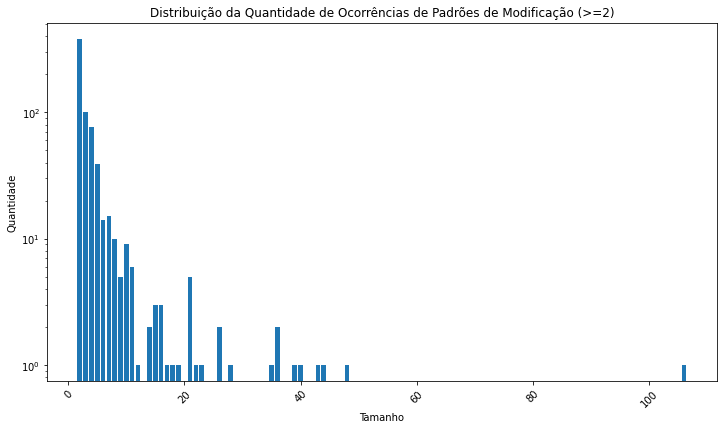

In [ ]:
plot_distribuicao_tamanhos(elementos)

In [ ]:
soma = 0
for item in elementos.values():
  soma = soma + item
print(soma)

686


Métricas das instâncias dos padrões

In [ ]:
principais_padroes = ['#2140','#2261','#7105','#7175']

In [ ]:
#ler arquivo zip
import zipfile
import json

#multipattern_zip = zipfile.ZipFile(f"{base}/metadata/{repository}/multipattern.zip", "r")
def read_file_from_zip(zipfile, file):
  data = zipfile.read(file)
  return json.loads(data.decode("utf-8"))

In [ ]:
#ler arquivo zip
import pandas as pd
import csv
import io

def read_csv_from_zip(zipfile, file):
  item = zipfile.read(file)
  reader = csv.DictReader(io.StringIO(item.decode("utf-8") ))
  result = []
  for row in reader:
    result.append(row)
  return result

In [ ]:
# obtem as métricas de um arquivo
def get_metrics(data, file):
  #obtem as métricas com o nome exato do arquivo
  if file in data:
    return data[file]
  #obtem as métricas com o nome parcial do arquivo
  for filename in data.keys():
    if filename in file:
      return data[filename]

  keys = ["cbo", "dit", "lcom", "loc", "nosi", "numberOfFields", "numberOfMethods", "rfc", "wmc"]
  result = {}
  for key in keys:
    result[key] = 0.0
  return result

In [ ]:
#leitura das métricas
metrics_zip = zipfile.ZipFile(f"{base}/metadata/{repository}/metrics.zip")
#print(metrics_zip)

#item = read_csv_from_zip(metrics_zip, '213db3b657692bd0e27a34f0daf4279cf7aba59a.csv')

def read_metrics(commit):
  #path = f"{metrics_base_folder}/{commit}.csv"
  #file = File(path).read()
  file = read_csv_from_zip(metrics_zip, f"{commit}.csv")
  result = {}
  for item in file:
    filename = item.get("filename")
    del item["filename"]
    data = { key: float(value) for key, value in item.items() }
    result[filename] = data
  return result

In [ ]:
metrics = ["dit", "wmc", "cbo", "lcom"]

def manutenability(change):
  code = f"#{change['code']}"
  position = 0
  measures = []

  tamanho = len(change["commits"])
  for current in change["commits"]:
    mapping = change["items"][position]
    position = position + 1
    if tamanho == 1 or (tamanho > 1 and (mapping["type"] == "move" or mapping["type"] == "update")):
      values = {
        "before": {},
        "after": {},
      }

      before = commits_file[commits_file.index(current) - 1]
      metrics_current = read_metrics(current)
      metrics_before = read_metrics(before)
      if ("newFile" in mapping) and ("oldFile" in mapping):
        if mapping["oldFile"] == mapping["newFile"]:
          old_metrics = get_metrics(metrics_before, mapping["oldFile"])
          new_metrics = get_metrics(metrics_current, mapping["newFile"])
          for key in old_metrics.keys():
            values["before"][key] = old_metrics[key]
            values["after"][key] = new_metrics[key]
        else: 
          old_a = get_metrics(metrics_before, mapping["oldFile"])
          new_a = get_metrics(metrics_current, mapping["oldFile"])
          old_b = get_metrics(metrics_before, mapping["newFile"])
          new_b = get_metrics(metrics_current, mapping["newFile"])
          for key in old_a.keys():
            values["before"][key] = (old_a[key] + old_b[key])/2
            values["after"][key] = (new_a[key] + new_b[key])/2

      novo = {
          "dit": 0,
          "wmc": 0,
          "cbo": 0,
          "lcom": 0

      }
      for metric in metrics:
        if metric in values["before"]:
          before = values["before"][metric]
        else:
          before = 0
        if metric in values["after"]:
          after = values["after"][metric]
        else:
          after = 0

        novo[metric] = novo[metric] + (after - before)
      measures.append(novo)
  
  sum = {
    "dit": 0,
    "wmc": 0,
    "cbo": 0,
    "lcom": 0
  }
  for m in measures:
    sum["dit"] = sum["dit"] + m["dit"]
    sum["wmc"] = sum["wmc"] + m["wmc"]
    sum["cbo"] = sum["cbo"] + m["cbo"]
    sum["lcom"] = sum["lcom"] + m["lcom"]
  return {
    "dit": sum["dit"]/len(measures),
    "wmc": sum["wmc"]/len(measures),
    "cbo": sum["cbo"]/len(measures),
    "lcom": sum["lcom"]/len(measures)
  }

In [ ]:
data_file = File(f"{base}/metadata/{repository}/analise-multipattern.json").read()
relacao = {}
for key,value in data_file.items():
  for elemento in list(value.keys()):
    relacao[elemento] = key
#relacao

In [ ]:
clusters_zip = zipfile.ZipFile(f"{base}/metadata/{repository}/clusters.zip")
multipattern = zipfile.ZipFile(f"{base}/metadata/{repository}/multipattern.zip")

def metrics_of_pattern(index):
  print(f"{index} ======================== ")
  cluster = read_file_from_zip(clusters_zip, f"clusters/{index}.json")
  for item in cluster["items"]:
    commit = relacao[f"#{item}"]
    file = read_file_from_zip(multipattern, f"multipattern/{commit}/#{item}.json")
    item = manutenability(file)
    print(item)

for index in principais_padroes:
  metrics_of_pattern(index)
  

#2140 ======================== 
{'dit': 0.0, 'wmc': -4.0, 'cbo': -2.0, 'lcom': -77.0}
{'dit': 0.0, 'wmc': -4.0, 'cbo': -2.0, 'lcom': -77.0}
{'dit': 0.0, 'wmc': -4.0, 'cbo': -2.0, 'lcom': -77.0}
{'dit': 0.0, 'wmc': -4.0, 'cbo': -2.0, 'lcom': -77.0}
{'dit': 0.0, 'wmc': -2.0, 'cbo': 0.0, 'lcom': -73.0}
{'dit': 0.0, 'wmc': -2.0, 'cbo': 0.0, 'lcom': -73.0}
{'dit': 0.0, 'wmc': -2.0, 'cbo': 0.0, 'lcom': -73.0}
{'dit': 0.0, 'wmc': -2.0, 'cbo': 0.0, 'lcom': -73.0}
{'dit': 0.0, 'wmc': -2.0, 'cbo': 0.0, 'lcom': -73.0}
{'dit': 0.0, 'wmc': 2.0, 'cbo': -2.0, 'lcom': 53.0}
{'dit': 0.0, 'wmc': 0.0, 'cbo': 1.0, 'lcom': -19.0}
{'dit': 0.0, 'wmc': 2.0, 'cbo': 0.0, 'lcom': 65.0}
{'dit': 0.0, 'wmc': 2.0, 'cbo': 0.0, 'lcom': 65.0}
{'dit': 0.0, 'wmc': 2.0, 'cbo': 0.0, 'lcom': 65.0}
{'dit': 0.0, 'wmc': 2.0, 'cbo': 0.0, 'lcom': 65.0}
{'dit': 0.0, 'wmc': 2.0, 'cbo': 0.0, 'lcom': 65.0}
#2261 ======================== 
{'dit': 0.0, 'wmc': 0.0, 'cbo': 1.5, 'lcom': -5.0}
{'dit': 0.0, 'wmc': 0.0, 'cbo': 1.5, 'lcom': 